# 11 · Grounding: coordinate systems and off-by-N clicks
Level L2 · Part 2 · professional · ~30 min · builds on 10

## Goal
By the end you can convert a click point given by a model (pixels of a resized screenshot, or a 0-999 grid) into the CSS pixels Playwright clicks in, on a 2x screen, and prove the click hits the intended link with a hit test and a highlighted screenshot.

## The idea
**GUI grounding** is turning "open issue #1" into one point on the screen. The model finds the point on the image it saw, but the click happens in another coordinate system. Three of them meet here: **CSS pixels**, the page's own unit that `page.mouse.click` uses; device pixels, the screenshot's unit, which is CSS pixels times the **device scale factor** (2 on a Retina-style screen); and the model's space, which is a resized screenshot for Claude or **normalised coordinates** (a 0-999 grid) for Gemini. Convert in the wrong order, or with the wrong size, and the click lands N pixels off, sometimes on a different link.

Analogy: reading a distance off a map that was photocopied at 200%. Measure on the copy, then divide by the enlargement before you walk.

## Picture
```mermaid
flowchart LR
  M["model point<br/>resized px or 0-999"] -->|"÷ size the model saw"| F["fraction of the image<br/>0..1"]
  F -->|"× CSS size<br/>= screenshot ÷ scale factor"| C["CSS px"]
  C --> K["page.mouse.click"]
  C --> H["hit test + highlight"]
```

## Step by step

### 1. Start Pocket Tracker
Same as lessons 07–10: copy the app to a scratch folder, start uvicorn on a free port, poll `/health`.

In [1]:
import atexit, io, json, math, os, shutil, socket, subprocess, sys, time
from pathlib import Path
import httpx
from IPython.display import display
from PIL import Image, ImageDraw
from playwright.async_api import async_playwright, TimeoutError as PWTimeout   # async API, as in lesson 07

Copy the app, pick a free port, start the server and wait until it answers.

In [2]:
WORK, REPO = Path("../work/11"), Path("../work/11/pocket_tracker")
shutil.rmtree(WORK, ignore_errors=True)
shutil.copytree("../apps/pocket_tracker", REPO, ignore=shutil.ignore_patterns("*.db", "__pycache__", ".pytest_cache"))
with socket.socket() as s:
    s.bind(("127.0.0.1", 0))
    PORT = s.getsockname()[1]
BASE = f"http://127.0.0.1:{PORT}"
env = {**os.environ, "POCKET_TRACKER_DB": str((WORK / "pocket_tracker.db").resolve())}
log = open(WORK / "server.log", "w")
server = subprocess.Popen([sys.executable, "-m", "uvicorn", "app:app", "--host", "127.0.0.1",
                           "--port", str(PORT)], cwd=REPO, env=env, stdout=log, stderr=log)
atexit.register(server.terminate)
deadline = time.time() + 15
while True:
    try:
        print("health:", httpx.get(f"{BASE}/health").json()); break
    except httpx.ConnectError:
        if time.time() > deadline or server.poll() is not None:
            raise RuntimeError("server did not start; see ../work/11/server.log")
        time.sleep(0.2)

health: {'status': 'ok'}


### 2. Browser and fallback
Browser cells are tagged `needs-download`. When they are skipped, `seen` and the screenshot come from the **recorded output** of a real run in `../data/recorded/` (`11.json` and `11_issues_dpr2.png`), so every later cell still works on real geometry.

In [3]:
out = subprocess.run([sys.executable, "-m", "playwright", "install", "chromium"], capture_output=True, text=True)
print("playwright install chromium -> exit code", out.returncode)

⏭  Skipped: this cell needs [download]. Run it yourself, or re-run with TUT_ENABLE=download.


Load the recording as the starting value of `seen`; live cells overwrite it.

In [4]:
REC = Path("../data/recorded")
REC_PATH, SHOT_PATH = REC / "11.json", REC / "11_issues_dpr2.png"
seen = json.loads(REC_PATH.read_text()) if REC_PATH.exists() else {}
seen["source"] = "recorded output (real run, saved earlier)"
print("fallback keys:", sorted(k for k in seen if k != "source"))

fallback keys: ['boxes', 'browser', 'css_size', 'dpr', 'shot_css', 'shot_device']


### 3. Open the issue list on a 2x screen
`new_context(device_scale_factor=2)` makes Chromium behave like a Retina laptop: the layout is still 1024x768 CSS pixels, but every CSS pixel is drawn with 2x2 device pixels. We keep the browser open for later cells, read `window.devicePixelRatio`, take a screenshot, and save the box of every link and button (in CSS pixels, from `bounding_box()`).

In [5]:
pw = await async_playwright().start()
browser = await pw.chromium.launch()
page = await (await browser.new_context(viewport={"width": 1024, "height": 768},
                                        device_scale_factor=2)).new_page()
await page.goto(f"{BASE}/issues")
seen["dpr"], seen["css_size"] = await page.evaluate("[devicePixelRatio, [innerWidth, innerHeight]]")
png = await page.screenshot()                       # default scale="device"
Image.open(io.BytesIO(png)).save(WORK / "11_issues_dpr2.png"); SHOT_PATH = WORK / "11_issues_dpr2.png"
seen["shot_device"] = list(Image.open(io.BytesIO(png)).size)
seen["shot_css"] = list(Image.open(io.BytesIO(await page.screenshot(scale="css"))).size)
seen["boxes"] = []
for loc in await page.locator("a, button").all():
    text, href, b = (await loc.inner_text()).strip(), await loc.get_attribute("href"), await loc.bounding_box()
    name = f"#{href.rsplit('/', 1)[1]} {text}" if href and href[-1].isdigit() else text
    seen["boxes"].append({"name": name, "box": [round(b[k], 2) for k in ("x", "y", "width", "height")]})
seen["source"] = "live run"
print(len(seen["boxes"]), "links and buttons saved")

⏭  Skipped: this cell needs [download]. Run it yourself, or re-run with TUT_ENABLE=download.


What the browser reported:

In [6]:
print(f"[{seen['source']}]")
DPR = seen["dpr"]
CSS_W, CSS_H = seen["css_size"]
SHOT_W, SHOT_H = seen["shot_device"]
print(f"devicePixelRatio = {DPR}, viewport = {CSS_W}x{CSS_H} CSS px")
print(f"screenshot (scale='device') = {SHOT_W}x{SHOT_H} px, screenshot (scale='css') = {seen['shot_css']}")
for b in seen["boxes"][3:6]:
    print(f"  {b['name'][:32]:32} box (x, y, w, h) = {b['box']}")

[recorded output (real run, saved earlier)]
devicePixelRatio = 2, viewport = 1024x768 CSS px
screenshot (scale='device') = 2048x1536 px, screenshot (scale='css') = [1024, 768]
  Filter                           box (x, y, w, h) = [505.69, 174.88, 45.62, 21]
  #1 Login page broken             box (x, y, w, h) = [83.52, 274.88, 148.16, 19]
  #2 Search ignores capital letter box (x, y, w, h) = [83.52, 310.88, 234.48, 19]


The screenshot is 2048x1536, twice the viewport on each side. The boxes are in CSS pixels: issue links sit 36 px apart, each 19 px tall. `page.screenshot(scale="css")` gives a 1024x768 image instead, which we come back to at the end.

### 4. A hit test on the recorded boxes
To check a click without a browser, find which link or button's box contains the point. This is the same **hit-testing** idea as lesson 03, now on real boxes.

In [7]:
def hit(x, y):
    """Name of the link or button under CSS point (x, y), or None."""
    for b in seen["boxes"]:
        bx, by, bw, bh = b["box"]
        if bx <= x <= bx + bw and by <= y <= by + bh:
            return b["name"]
    return None

target = next(b for b in seen["boxes"] if b["name"].startswith("#1 "))
tx, ty, tw, th = target["box"]
AIM = (tx + 20, ty + th / 2)                       # a point inside the link text, not the centre; any point inside the box works
print("target:", target["name"], "| aim point (CSS px):", AIM, "| hit:", hit(*AIM))

target: #1 Login page broken | aim point (CSS px): (103.52, 284.38) | hit: #1 Login page broken


### 5. The same point in each model's space
No model runs in this lesson (lesson 12 adds one). We play the model: take the true aim point and express it the way each model would see it, rounded to whole numbers as models return them.
- Claude on the high-res tier gets the 2048x1536 screenshot as is (4070 tokens, under 4784), so it answers in device pixels.
- Claude on the standard tier needs the screenshot shrunk to `resized_size` from lesson 10: 1270x952.
- Gemini answers on a 0-999 grid whatever the image size.

In [8]:
def resized_size(width, height, max_edge=1568, max_tokens=1568):
    """Claude's reference implementation (vision-coordinates docs), copied from lesson 10."""
    def fits(w, h):
        return (math.ceil(w / 28) * 28 <= max_edge and math.ceil(h / 28) * 28 <= max_edge
                and math.ceil(w / 28) * math.ceil(h / 28) <= max_tokens)
    if fits(width, height):
        return (width, height)
    if height > width:
        rh, rw = resized_size(height, width, max_edge, max_tokens)
        return (rw, rh)
    aspect, lo, hi = width / height, 1, width
    while lo + 1 < hi:
        mid = (lo + hi) // 2
        lo, hi = (mid, hi) if fits(mid, max(round(mid / aspect), 1)) else (lo, mid)
    return (lo, max(round(lo / aspect), 1))

Each space is described by the size of the image the model saw. Our stand-in for the model maps a CSS point into that space.

In [9]:
SPACES = {"Claude high-res": resized_size(SHOT_W, SHOT_H, 2576, 4784),
          "Claude standard": resized_size(SHOT_W, SHOT_H),
          "Gemini 0-999": (1000, 1000)}

def play_model(css_x, css_y, size):
    """What a perfect model would answer: the CSS point in the space it saw, as integers."""
    mw, mh = size
    return (min(round(css_x / CSS_W * mw), mw - 1), min(round(css_y / CSS_H * mh), mh - 1))

answers = {name: play_model(*AIM, size) for name, size in SPACES.items()}
print("high-res tokens:", math.ceil(SHOT_W/28)*math.ceil(SHOT_H/28))
for name, size in SPACES.items():
    print(f"simulated model: {name:16} sees {size[0]}x{size[1]:<5} -> answers {answers[name]}")

high-res tokens: 4070
simulated model: Claude high-res  sees 2048x1536  -> answers (207, 569)
simulated model: Claude standard  sees 1270x952   -> answers (128, 353)
simulated model: Gemini 0-999     sees 1000x1000  -> answers (101, 370)


One point on the page, three different pairs of numbers. None of them is a CSS pixel.

### 6. The bug: clicking the model's numbers directly
The most common harness bug passes the model's answer straight to `page.mouse.click`. On a 1x screen with an unresized screenshot that happens to work, which is why the bug survives until the agent runs on a 2x laptop.

In [10]:
for name, (mx, my) in answers.items():
    print(f"{name:16} click({mx}, {my}) -> hits {hit(mx, my)}")

Claude high-res  click(207, 569) -> hits #9 Due dates on issues
Claude standard  click(128, 353) -> hits #3 Typo on the About page: 'Trakcer' should be 'Tracker'
Gemini 0-999     click(101, 370) -> hits None


The high-res answer (207, 569) is in device pixels, twice the CSS point, and lands on the link of issue #9 about 285 CSS px lower (eight rows). The agent opens the wrong issue and may report a confident, wrong bug. The standard-tier answer (128, 353) lands on issue #3, two rows down; the Gemini answer hits nothing.

Draw both points on the screenshot to see it. The screenshot is in device pixels, so a CSS point is drawn at `DPR` times its coordinates.

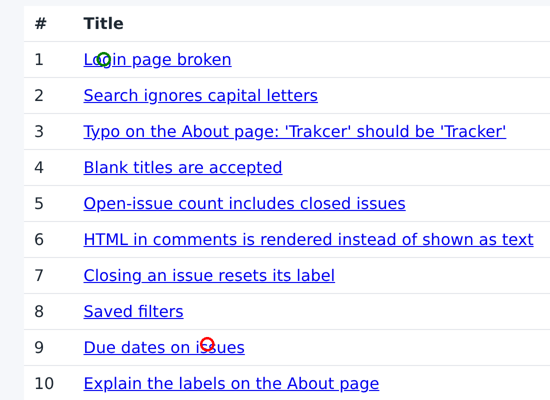

In [11]:
shot = Image.open(SHOT_PATH).convert("RGB")
draw = ImageDraw.Draw(shot)
def ring(css_xy, colour):
    x, y = css_xy[0] * DPR, css_xy[1] * DPR
    draw.ellipse((x - 14, y - 14, x + 14, y + 14), outline=colour, width=5)

ring(AIM, "green")                                  # where the model meant
ring(answers["Claude high-res"], "red")             # where the buggy harness clicked
display(shot.crop((0, 450, 1100, 1250)).resize((550, 400)))

Green: the first word of "Login page broken", where the model pointed. Red: "Due dates on issues", eight rows down, where the click went.

### 7. The fix: one conversion for every space
Divide by the size of the image the model saw to get a fraction of the screen, then multiply by the screen's size in CSS pixels. The CSS size is the screenshot size divided by the device scale factor; that is where the factor 2 goes. Clamp first, as Claude's docs advise, so a point just outside the image cannot leave the page.

In [12]:
def to_css(mx, my, size):
    mw, mh = size
    mx, my = min(max(mx, 0), mw), min(max(my, 0), mh)      # clamp to the image the model saw
    return (mx / mw * (SHOT_W / DPR), my / mh * (SHOT_H / DPR))

for name, size in SPACES.items():
    cx, cy = to_css(*answers[name], size)
    print(f"{name:16} {answers[name]} -> CSS ({cx:6.1f}, {cy:6.1f}), "
          f"off by ({cx - AIM[0]:+.1f}, {cy - AIM[1]:+.1f}) px -> hits {hit(cx, cy)}")

Claude high-res  (207, 569) -> CSS ( 103.5,  284.5), off by (-0.0, +0.1) px -> hits #1 Login page broken
Claude standard  (128, 353) -> CSS ( 103.2,  284.8), off by (-0.3, +0.4) px -> hits #1 Login page broken
Gemini 0-999     (101, 370) -> CSS ( 103.4,  284.2), off by (-0.1, -0.2) px -> hits #1 Login page broken


All three land on issue #1, within half a CSS pixel of the aim point. The small leftover error is the model's rounding: one model pixel is 0.5 CSS px at high-res, 0.8 on the standard tier and about 1 on the Gemini grid. For Gemini the formula is the docs' `x / 1000 * width`, with width in CSS pixels.

### 8. Verify in the real browser
Geometry on saved boxes is a model of the page. The browser has the last word: `document.elementFromPoint(x, y)` returns the element at a CSS point, and a real click shows which URL opens.

In [13]:
probe = "([x, y]) => { const e = document.elementFromPoint(x, y); return e ? e.tagName + ' ' + e.textContent.trim().slice(0, 25) : null }"
seen["browser"] = {}
points = {"buggy": answers["Claude high-res"],
          "fixed": to_css(*answers["Claude standard"], SPACES["Claude standard"])}
for label, (x, y) in points.items():
    element = await page.evaluate(probe, [x, y])
    try:
        async with page.expect_navigation(timeout=3000):   # wait for the page the click opens
            await page.mouse.click(x, y)
    except PWTimeout:
        pass                                               # the click opened nothing
    seen["browser"][label] = {"point": [round(x, 1), round(y, 1)], "element": element, "url": page.url.replace(BASE, "")}
    await page.goto(f"{BASE}/issues")
print("checked in Chromium")

⏭  Skipped: this cell needs [download]. Run it yourself, or re-run with TUT_ENABLE=download.


What the browser found:

In [14]:
print(f"[{seen['source']}]")
for label, r in seen.get("browser", {}).items():
    print(f"{label:6} click at {r['point']}: element {r['element']!r} -> opened {r['url']}")

[recorded output (real run, saved earlier)]
buggy  click at [207, 569]: element 'A Due dates on issues' -> opened /issues/9
fixed  click at [103.2, 284.8]: element 'A Login page broken' -> opened /issues/1


The buggy click really opened `/issues/9`; the converted one opened `/issues/1`. The saved-box hit test and the browser agree.

### 9. Off-by-N: wrong sizes that almost work
The factor-2 bug is loud. Quieter bugs scale by a size that is close but wrong. Each line below converts the standard-tier or Gemini answer with one wrong size and reports the miss in CSS pixels, at our aim point and at the right edge of the screen (x = 1000).

In [15]:
std, gem = answers["Claude standard"], answers["Gemini 0-999"]
mistakes = {
    "edge-limit size 1568x1176 (not resized_size)": (std, (1568, 1176), SPACES["Claude standard"]),
    "padded size 1288x952 (multiple of 28)": (std, (1288, 952), SPACES["Claude standard"]),
    "wrong tier: assumed high-res 2048x1536": (std, (2048, 1536), SPACES["Claude standard"]),
    "Gemini divided by 999, not 1000": (gem, (999, 999), (1000, 1000))}
for name, (ans, wrong, right) in mistakes.items():
    cx, cy = to_css(*ans, wrong)
    edge_ans = play_model(1000, AIM[1], right)
    edge_err = to_css(*edge_ans, wrong)[0] - to_css(*edge_ans, right)[0]
    print(f"{name:45} off by ({cx - AIM[0]:+6.1f}, {cy - AIM[1]:+6.1f}), at x=1000 {edge_err:+6.1f} px -> {hit(cx, cy)}")

edge-limit size 1568x1176 (not resized_size)  off by ( -19.9,  -53.8), at x=1000 -190.0 px -> None
padded size 1288x952 (multiple of 28)         off by (  -1.8,   +0.4), at x=1000  -14.0 px -> #1 Login page broken
wrong tier: assumed high-res 2048x1536        off by ( -39.5, -107.9), at x=1000 -379.8 px -> None
Gemini divided by 999, not 1000               off by (  +0.0,   +0.1), at x=1000   +1.0 px -> #1 Login page broken


- Using the edge-limit size or the wrong tier shrinks every point toward the top-left corner, by 19% or 38%: 54 or 108 px too high here, and 190 or 380 px too far left at the right edge. Both miss.
- The padded size (Claude pads to a multiple of 28; its docs say to divide by the resized size, not the padded one) is wrong only horizontally, by 1.4% (1288 vs 1270); 952 is already a multiple of 28, so y is unaffected. That is 2 px here and 14 px at the right edge. A hit here, a miss on a small target near the right.
- Dividing by 999 is off by 0.1%: at most 1 px at 1024 px wide.

The bigger the screen and the smaller the target, the more these near-misses matter. Rows here are 19 px tall; a 14 px miss on a 12 px checkbox is a miss.

### 10. Two ways to make the factor disappear
You can remove one conversion instead of getting it right every time:
- `page.screenshot(scale="css")` returned a 1024x768 image on the 2x screen (step 3), so device pixels equal CSS pixels. Text is drawn at half the resolution, and you pay for fewer tokens.
- A viewport with `device_scale_factor=1` (the default in Playwright) does the same for every screenshot.

You still need the model-space step whenever the model sees a resized image or a grid.

The last browser cells save the recording and close the browser.

In [16]:
REC.mkdir(parents=True, exist_ok=True)
REC_PATH.write_text(json.dumps({k: v for k, v in seen.items() if k != "source"}, indent=1) + "\n")
shutil.copy(WORK / "11_issues_dpr2.png", REC / "11_issues_dpr2.png")
await browser.close()
await pw.stop()
print("saved", REC_PATH, "and 11_issues_dpr2.png; browser closed")

⏭  Skipped: this cell needs [download]. Run it yourself, or re-run with TUT_ENABLE=download.


## At work
- OSWorld names GUI grounding as a main reason vision agents fail. Teams log the screenshot, the model's raw point and the converted point for every click, so a miss can be replayed → lesson 12.
- Claude's computer-use and browser-use tools reject oversized screenshots, so the harness resizes, then scales Claude's point back and divides by the display scale factor on HiDPI screens, as Claude's docs describe → lesson 13.
- Gemini's computer-use tool answers on a 0-999 grid that the harness must convert with the real screen size; OpenAI's tool uses its own convention → lesson 13a.
- Claude's docs warn that Claude works best with pixel coordinates, not normalised ones. They also offer `transformations: {"oversized_image": "error"}`, which makes a silent resize (the harness resizing with the wrong limits, as above) a visible 400 error. Where a DOM exists, many teams click by element reference instead and avoid grounding entirely → lesson 27a.

## What just happened
- On a 2x screen (`device_scale_factor=2`) the 1024x768 viewport gave a 2048x1536 screenshot, while `page.mouse.click` and `bounding_box()` stayed in CSS pixels.
- The same aim point was (207, 569), (128, 353) and (101, 370) in three model spaces; none was a CSS pixel.
- Clicking the high-res answer directly opened issue #9 instead of #1, in the saved boxes and in the real browser.
- One conversion fixed all three: divide by the size the model saw, multiply by screenshot size ÷ device scale factor.
- Near-miss sizes (edge limit, padding, wrong tier) gave errors that grow toward the right and bottom of the screen.

## Common mistakes
Using the wrong Claude tier's limits. The harness assumes a high-res model and treats the answer as device pixels, but the model is on the standard tier and saw the 1270x952 image. `click_check` stands for the step that compares the clicked element with the one the agent meant to click.

In [17]:
def click_check(css_xy, expected):
    got = hit(*css_xy)
    if got != expected:
        raise AssertionError(f"click at ({css_xy[0]:.0f}, {css_xy[1]:.0f}) hit {got!r}, expected {expected!r}")
    return f"ok: {got}"

wrong_size = resized_size(SHOT_W, SHOT_H, 2576, 4784)          # high-res limits: 2048x1536, no resize
click_check(to_css(*answers["Claude standard"], wrong_size), target["name"])

AssertionError: click at (64, 176) hit None, expected '#1 Login page broken'

Fix: compute the size with the limits of the model you actually called (here the standard tier: 1568 px, 1568 tokens).

In [18]:
right_size = resized_size(SHOT_W, SHOT_H)                      # standard tier: 1270x952
print(right_size, click_check(to_css(*answers["Claude standard"], right_size), target["name"]))

(1270, 952) ok: #1 Login page broken


Two more:
- Drawing a check mark on the screenshot at the CSS point. The screenshot is in device pixels, so the mark lands at half the distance and the check "passes" on the wrong spot. Multiply by the device scale factor when drawing, as `ring` did.
- Converting with the size of an earlier screenshot after the window was resized. Coordinates are valid only for the screenshot the model saw. Keep the size next to each screenshot (lesson 03).

## Try it
The same page on a 1.5x laptop screen: viewport 1024x768, `device_scale_factor=1.5`, so the screenshot is 1536x1152 (the CSS boxes do not change). Play a standard-tier Claude model aiming at the centre of the **Filter** button: compute the size it sees, its answer, and convert it back with a version of `to_css` that takes the scale factor as an argument. Check the hit. Then show what a harness that hard-codes a factor of 2 would hit.

In [19]:
# your code here

## Key terms
- **GUI grounding** — mapping what the agent wants to click to a point on the screen; the step where vision agents most often fail.
- **CSS pixel** — the page's own unit of length; viewports, `bounding_box()` and `page.mouse.click` all use it.
- **device scale factor** — device pixels per CSS pixel (`window.devicePixelRatio`; 2 on Retina-style screens); a screenshot is the viewport times this factor unless taken with `scale="css"`.
- **normalised coordinates** — a point given as a fraction of the image on a fixed grid (Gemini: 0-999) instead of in pixels; convert with `x / 1000 * width`.

Always run this cell last: it stops the server.

In [20]:
server.terminate()
try:
    server.wait(timeout=10)
except subprocess.TimeoutExpired:
    server.kill(); server.wait()
log.close()
print("server stopped, exit code", server.returncode)

server stopped, exit code -15
